# Semana 10 · Mini-proyecto de datos (cierre del Corte 2)

**Caso:** Spotify — capacidad de streaming y curaduría regional · **Autor:** Julián Andrés Solano Ledesma

Flujo completo, integrando lo construido en el corte:

| Etapa | Qué se reutiliza |
|---|---|
| **Modelo** | ERD y esquema SQL de la Semana 6 |
| **Extraer** | CSV de Kaggle + API de MusicBrainz (Semana 8) |
| **Limpiar** | `limpieza_spotify.py` de la Semana 9 |
| **Cargar** | Tablas del ERD en `datos/spotify.db` (SQLite) |
| **Analizar** | 2 consultas SQL con filtro + agregación (Semana 7), verificadas en pandas |

## 1. Ejecutar el pipeline: extraer → limpiar → cargar

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import pipeline_spotify as P

r = P.ejecutar(usar_cache=True)   # usa la caché de la API; con False vuelve a consultar MusicBrainz
print(f"SQLite {sqlite3.sqlite_version}")

SQLite 3.45.3


### 1.1 Extraer

In [2]:
print(f"CSV de Kaggle: {r['crudo'].shape[0]} filas × {r['crudo'].shape[1]} columnas")
r["crudo"].head(3)

CSV de Kaggle: 500 filas × 12 columnas


,Country,Artist,Album,Genre,Release Year,Monthly Listeners (Millions),Total Streams (Millions),Total Hours Streamed (Millions),Avg Stream Duration (Min),Platform Type,Streams Last 30 Days (Millions),Skip Rate (%)
0,Germany,Taylor Swift,1989 (Taylor's Version),K-pop,2019,23.1,3695.53,14240.35,4.28,Free,118.51,2.24
1,Brazil,The Weeknd,After Hours,R&B,2022,60.6,2828.16,11120.44,3.9,Premium,44.87,23.98
2,United States,Post Malone,Austin,Reggaeton,2023,42.84,1425.46,4177.49,4.03,Free,19.46,4.77


In [3]:
# API de MusicBrainz: género con más votos de la comunidad para los 15 artistas
r["api"][["artist_id", "nombre", "tipo", "pais_iso", "genero_principal", "coincidencia_pct"]]

,artist_id,nombre,tipo,pais_iso,genero_principal,coincidencia_pct
0,1,Ariana Grande,Person,US,pop,100
1,2,BLACKPINK,Group,KR,k-pop,100
2,3,BTS,Group,KR,k-pop,100
3,4,Bad Bunny,Person,PR,reggaeton,100
4,5,Billie Eilish,Person,US,electropop,100
5,6,Doja Cat,Person,US,hip hop,100
6,7,Drake,Person,CA,hip hop,100
7,8,Dua Lipa,Person,GB,dance-pop,100
8,9,Ed Sheeran,Person,GB,pop,100
9,10,KAROL G,Person,CO,reggaeton,100


### 1.2 Limpiar (script de la Semana 9)

Sobre el CSV **real**, sin ensuciar, la limpieza solo encuentra los dos problemas que trae el archivo: los años de lanzamiento inconsistentes y las filas imposibles.

In [4]:
r["bitacora"][["paso", "dimensión", "detalle", "filas antes", "filas después"]]

,paso,dimensión,detalle,filas antes,filas después
0,1. Nombres de columna,Consistencia,12 columnas a snake_case (modelo Semana 6),500,500
1,2. Formato de texto,Consistencia,0 celdas llevadas a su valor oficial; 0 fuera ...,500,500
2,3. Tipos,Exactitud,6 medidas a float64 y el año a Int16 (0 celdas...,500,500
3,4. Duplicados,Unicidad,0 filas repetidas eliminadas,500,500
4,5. Faltantes,Completitud,0 filas sin país/género eliminadas; 0 medidas ...,500,500
5,6. Año por álbum,Consistencia,368 celdas corregidas a un año por álbum,500,500
6,7. Valores imposibles,Exactitud,2 filas con streams 30 d > streams totales,500,498


In [5]:
limpio = r["limpio"]
calidad = pd.DataFrame({
    "Antes": {"Filas": len(r["crudo"]),
              "Celdas nulas": int(r["crudo"].isna().sum().sum()),
              "Duplicados exactos": int(r["crudo"].duplicated().sum()),
              "Álbumes con más de un año": int((r["crudo"].groupby("Album")["Release Year"].nunique() > 1).sum()),
              "Filas imposibles (30 d > total)": int((pd.to_numeric(r["crudo"]["Streams Last 30 Days (Millions)"])
                                                     > pd.to_numeric(r["crudo"]["Total Streams (Millions)"])).sum())},
    "Después": {"Filas": len(limpio),
                "Celdas nulas": int(limpio.isna().sum().sum()),
                "Duplicados exactos": int(limpio.duplicated().sum()),
                "Álbumes con más de un año": int((limpio.groupby("album", observed=True)["anio_lanzamiento"].nunique() > 1).sum()),
                "Filas imposibles (30 d > total)": int((limpio["streams_30d_m"] > limpio["streams_totales_m"]).sum())},
})
calidad

,Antes,Después
Filas,500,498
Celdas nulas,0,0
Duplicados exactos,0,0
Álbumes con más de un año,15,0
Filas imposibles (30 d > total),2,0


### 1.3 Cargar en el modelo (ERD de la Semana 6)

In [6]:
con = sqlite3.connect(P.BASE)
print("Violaciones de FK:", con.execute("PRAGMA foreign_key_check").fetchall() or "ninguna")
pd.DataFrame({t: [con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]] for t in r["tablas"]}, index=["filas"])

Violaciones de FK: ninguna


,pais,genero,plan_suscripcion,artista,album,metrica_streaming
filas,20,10,2,15,15,498


In [7]:
# La API completó la columna que estaba vacía desde la Semana 6
pd.read_sql("SELECT artist_id, nombre, genero_principal FROM artista", con).head(6)

,artist_id,nombre,genero_principal
0,1,Ariana Grande,pop
1,2,BLACKPINK,k-pop
2,3,BTS,k-pop
3,4,Bad Bunny,reggaeton
4,5,Billie Eilish,electropop
5,6,Doja Cat,hip hop


## 2. Análisis con consultas (filtro + agregación)

In [8]:
import re

sql = Path("consultas-mini-proyecto.sql").read_text(encoding="utf-8")
Q1, Q2 = [q.strip() for q in re.sub(r"--.*", "", sql).split(";") if q.strip()]

# Una vista desnormalizada para replicar las consultas en pandas
m = r["tablas"]["metrica_streaming"]
vista = (m.merge(r["tablas"]["pais"].rename(columns={"nombre": "pais"}), on="country_id")
          .merge(r["tablas"]["plan_suscripcion"].rename(columns={"nombre": "plan"}), on="plan_id")
          .merge(r["tablas"]["album"], on="album_id")
          .merge(r["tablas"]["artista"].rename(columns={"nombre": "artista"}), on="artist_id"))

### Q1 · Capacidad: ¿qué regiones concentran la demanda Premium de los últimos 30 días?

**Filtro:** `plan = 'Premium'` · **Agregación:** suma por región, participación y promedio por país.

In [9]:
q1 = pd.read_sql(Q1, con)
q1

,region,paises,registros,streams_30d_total_m,participacion_pct,streams_30d_por_pais_m
0,Europa,8,106,10815.88,43.2,1351.98
1,Asia,5,49,4961.87,19.8,992.37
2,Latinoamérica,3,48,4387.74,17.5,1462.58
3,Norteamérica,2,22,2277.67,9.1,1138.84
4,África,1,17,1794.71,7.2,1794.71
5,Oceanía,1,8,816.32,3.3,816.32


In [10]:
prem = vista[vista["plan"] == "Premium"]
q1_pd = (prem.groupby("region")
             .agg(paises=("country_id", "nunique"), registros=("metric_id", "count"),
                  streams_30d_total_m=("streams_30d_m", "sum"))
             .sort_values("streams_30d_total_m", ascending=False).reset_index())
q1_pd["participacion_pct"] = (100 * q1_pd["streams_30d_total_m"] / q1_pd["streams_30d_total_m"].sum()).round(1)
q1_pd["streams_30d_por_pais_m"] = (q1_pd["streams_30d_total_m"] / q1_pd["paises"]).round(2)
q1_pd["streams_30d_total_m"] = q1_pd["streams_30d_total_m"].round(2)
# Tolerancia de 0,01: SQLite y pandas redondean distinto los valores terminados en 5
pd.testing.assert_frame_equal(q1, q1_pd[q1.columns], check_dtype=False, check_exact=False, rtol=0, atol=0.011)
print("OK: SQL y pandas coinciden en Q1.")

OK: SQL y pandas coinciden en Q1.


### Q2 · Curaduría: en Latinoamérica, ¿qué artistas acumulan más demanda reciente?

**Filtro:** `region = 'Latinoamérica'` · **Agregación:** suma de streams y *skip rate* promedio por artista, con el género de MusicBrainz.

In [11]:
q2 = pd.read_sql(Q2, con)
q2

,artista,genero_musicbrainz,registros,streams_30d_total_m,skip_rate_prom_pct
0,Ariana Grande,pop,8,883.21,20.27
1,Ed Sheeran,pop,6,783.15,21.20
2,Taylor Swift,pop,6,737.60,14.44
3,Doja Cat,hip hop,6,685.51,27.13
4,BTS,k-pop,5,681.60,19.17
5,The Weeknd,r&b,6,667.41,13.44
6,Bad Bunny,reggaeton,6,659.88,23.70
7,Dua Lipa,dance-pop,5,656.09,26.69
8,BLACKPINK,k-pop,7,608.88,16.37
9,Billie Eilish,electropop,4,436.60,29.15


In [12]:
lat = vista[vista["region"] == "Latinoamérica"]
q2_pd = (lat.groupby(["artista", "genero_principal"])
            .agg(registros=("metric_id", "count"),
                 streams_30d_total_m=("streams_30d_m", "sum"),
                 skip_rate_prom_pct=("skip_rate_pct", "mean"))
            .round(2).sort_values("streams_30d_total_m", ascending=False).reset_index()
            .rename(columns={"genero_principal": "genero_musicbrainz"}))
# Tolerancia de 0,01: SQLite y pandas redondean distinto los valores terminados en 5 (p. ej. 27,125)
pd.testing.assert_frame_equal(q2, q2_pd, check_dtype=False, check_exact=False, rtol=0, atol=0.011)
print("OK: SQL y pandas coinciden en Q2.")

OK: SQL y pandas coinciden en Q2.


## 3. Gráficos de los resultados

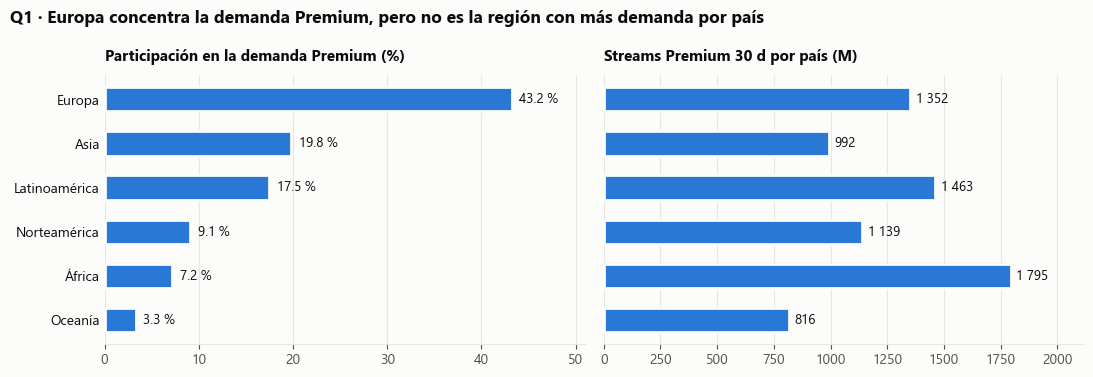

In [13]:
AZUL, NARANJA = "#2a78d6", "#eb6834"          # paleta validada (contraste y daltonismo)
TINTA, TINTA2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e7e6e2", "#fcfcfb"
plt.rcParams.update({"font.family": "Segoe UI", "font.size": 10, "axes.edgecolor": REJILLA,
                     "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA,
                     "figure.facecolor": FONDO, "axes.facecolor": FONDO, "svg.fonttype": "none"})
Path("img").mkdir(exist_ok=True)


def barras(ax, etiquetas, valores, colores, fmt, titulo):
    y = range(len(etiquetas))[::-1]
    ax.barh(list(y), valores, height=0.55, color=colores, edgecolor=FONDO, linewidth=2)
    ax.set_yticks(list(y), etiquetas)
    ax.set_title(titulo, loc="left", fontsize=11, color=TINTA, fontweight="bold", pad=10)
    ax.xaxis.grid(True, color=REJILLA, linewidth=0.8); ax.set_axisbelow(True)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="y", length=0)
    return list(y)


fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
ys = barras(a1, q1["region"], q1["participacion_pct"], AZUL, "{:.1f} %", "Participación en la demanda Premium (%)")
for y, v in zip(ys, q1["participacion_pct"]):
    a1.text(v + 0.8, y, f"{v:.1f} %", va="center", color=TINTA, fontsize=9.5)
a1.set_xlim(0, q1["participacion_pct"].max() * 1.18)
ys = barras(a2, q1["region"], q1["streams_30d_por_pais_m"], AZUL, "{:,.0f}", "Streams Premium 30 d por país (M)")
for y, v in zip(ys, q1["streams_30d_por_pais_m"]):
    a2.text(v + 25, y, f"{v:,.0f}".replace(",", " "), va="center", color=TINTA, fontsize=9.5)
a2.set_xlim(0, q1["streams_30d_por_pais_m"].max() * 1.18)
fig.suptitle("Q1 · Europa concentra la demanda Premium, pero no es la región con más demanda por país",
             x=0.01, ha="left", fontsize=12.5, fontweight="bold", color=TINTA)
fig.tight_layout()
fig.savefig("img/q1-demanda-premium-region.svg", bbox_inches="tight")
plt.show()

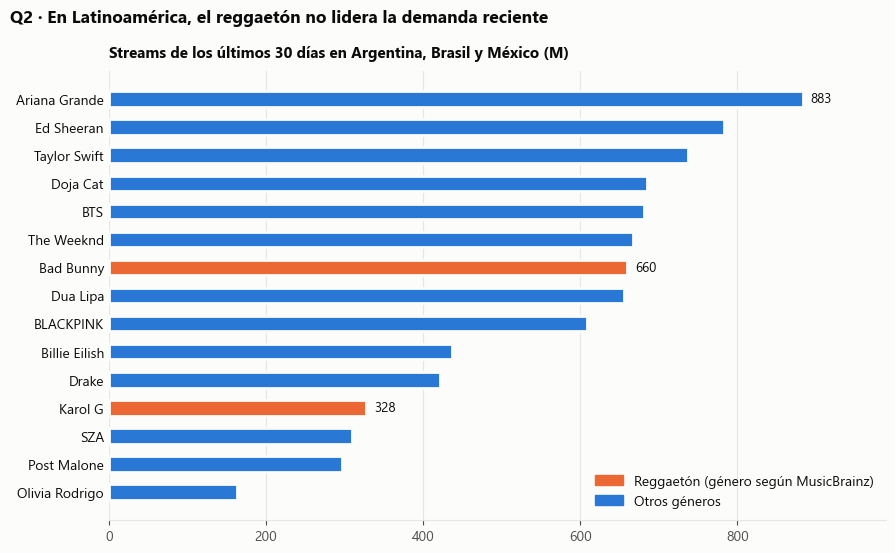

In [14]:
reg = q2["genero_musicbrainz"].eq("reggaeton")
fig, ax = plt.subplots(figsize=(9, 5.6))
ys = barras(ax, q2["artista"], q2["streams_30d_total_m"], [NARANJA if g else AZUL for g in reg],
            "{:,.0f}", "Streams de los últimos 30 días en Argentina, Brasil y México (M)")
for y, v, rg, top in zip(ys, q2["streams_30d_total_m"], reg, range(len(q2))):
    if rg or top == 0:                                   # etiquetas selectivas: el líder y el reggaetón
        ax.text(v + 10, y, f"{v:,.0f}".replace(",", " "), va="center", color=TINTA, fontsize=9.5)
ax.set_xlim(0, q2["streams_30d_total_m"].max() * 1.12)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=NARANJA), plt.Rectangle((0, 0), 1, 1, color=AZUL)],
          labels=["Reggaetón (género según MusicBrainz)", "Otros géneros"],
          loc="lower right", frameon=False, labelcolor=TINTA)
fig.suptitle("Q2 · En Latinoamérica, el reggaetón no lidera la demanda reciente",
             x=0.01, ha="left", fontsize=12.5, fontweight="bold", color=TINTA)
fig.tight_layout()
fig.savefig("img/q2-artistas-latinoamerica.svg", bbox_inches="tight")
plt.show()
con.close()